In [1]:
import pandas as pd

# Replace 'HST_polar_flare...' with the actual file name and extension (e.g., .csv, .xlsx)
file_name = 'HST_polar_flare_2019april02_shifted_power_region_time_shifted.txt'  # Update with the correct file name
df = pd.read_csv(file_name)  # Use pd.read_excel(file_name) if it's an Excel file

# Display the first few rows of the DataFrame
df.head()

,2019-04-02/00:57:22.509 1.5367964e+11
0,2019-04-02/00:58:22.509 1.7680605e+11
1,2019-04-02/00:59:22.509 1.3731888e+11
2,2019-04-02/01:00:22.509 1.9800583e+11
3,2019-04-02/01:01:22.509 3.2838546e+11
4,2019-04-02/01:02:22.509 2.4387079e+11


In [2]:
df[['time', 'rayleigh']] = df.iloc[:, 0].str.split(expand=True)
df.head()

,2019-04-02/00:57:22.509 1.5367964e+11,time,rayleigh
0,2019-04-02/00:58:22.509 1.7680605e+11,2019-04-02/00:58:22.509,1.7680605e+11
1,2019-04-02/00:59:22.509 1.3731888e+11,2019-04-02/00:59:22.509,1.3731888e+11
2,2019-04-02/01:00:22.509 1.9800583e+11,2019-04-02/01:00:22.509,1.9800583e+11
3,2019-04-02/01:01:22.509 3.2838546e+11,2019-04-02/01:01:22.509,3.2838546e+11
4,2019-04-02/01:02:22.509 2.4387079e+11,2019-04-02/01:02:22.509,2.4387079e+11


In [3]:
df = df.drop(df.columns[0], axis=1)
df.head()

,time,rayleigh
0,2019-04-02/00:58:22.509,1.7680605e+11
1,2019-04-02/00:59:22.509,1.3731888e+11
2,2019-04-02/01:00:22.509,1.9800583e+11
3,2019-04-02/01:01:22.509,3.2838546e+11
4,2019-04-02/01:02:22.509,2.4387079e+11


In [4]:
df['time'] = pd.to_datetime(df['time'], format='%Y-%m-%d/%H:%M:%S.%f')
df.head()


,time,rayleigh
0,2019-04-02 00:58:22.509,1.7680605e+11
1,2019-04-02 00:59:22.509,1.3731888e+11
2,2019-04-02 01:00:22.509,1.9800583e+11
3,2019-04-02 01:01:22.509,3.2838546e+11
4,2019-04-02 01:02:22.509,2.4387079e+11


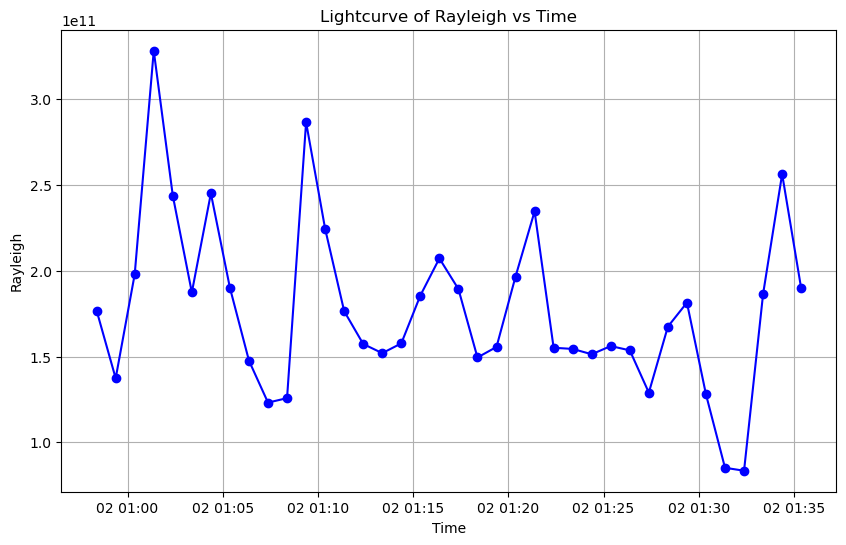

In [6]:
import matplotlib.pyplot as plt

# Plot the lightcurve
plt.figure(figsize=(10, 6))
plt.plot(df['time'], df['rayleigh'], marker='o', linestyle='-', color='b')
plt.title('Lightcurve of Rayleigh vs Time')
plt.xlabel('Time')
plt.ylabel('Rayleigh')
plt.grid()
plt.show()

/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_27515/4124806743.py:17: RuntimeWarning: divide by zero encountered in divide
  plt.plot((1/frequencies[:len(frequencies)//2])/60, np.abs(fft_result)[:len(fft_result)//2])


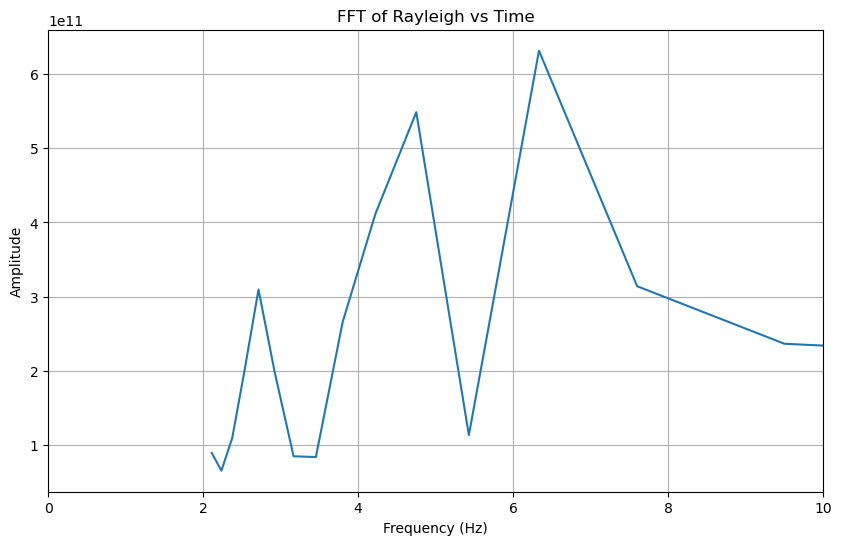

In [10]:
import numpy as np

import matplotlib.pyplot as plt

# Convert 'rayleigh' column to numeric
df['rayleigh'] = pd.to_numeric(df['rayleigh'])

# Calculate the time difference (assuming uniform sampling)
time_diff = (df['time'].iloc[1] - df['time'].iloc[0]).total_seconds()

# Perform FFT
fft_result = np.fft.fft(df['rayleigh'])
frequencies = np.fft.fftfreq(len(fft_result), d=time_diff)

# Plot the FFT result
plt.figure(figsize=(10, 6))
plt.plot((1/frequencies[:len(frequencies)//2])/60, np.abs(fft_result)[:len(fft_result)//2])
plt.title('FFT of Rayleigh vs Time')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.grid()
plt.xlim(0,10)
plt.show()